## Imports

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "coupling_sources").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not find the project root containing coupling_sources.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

MCMC_NUM_CHAINS: int = 3
MCMC_CHAIN_METHOD: str = "parallel"

import numpyro
numpyro.set_host_device_count(MCMC_NUM_CHAINS)

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scienceplots
from IPython.display import display

plt.style.use("science")

from coupling_sources import analysis as csa
from coupling_sources.core.inference import fit_mcmc
from coupling_sources.core.model import choice_model
from coupling_sources.core.simulation import simulate_choices
from coupling_sources.core.stimuli import generate_stimuli
from coupling_sources.utils.angles import centered_angle, circular_mean, optimal_weights
from coupling_sources.core.parameters.simulation import SimParams


In [2]:
N_SOURCES: int = 4
COUPLED: tuple[int, int] = (0, 1)

## Stimulus generator

In [3]:
SEED: int = 13
N_TRIALS_FULL: int = 20
N_TRIALS_PARTIAL: int = 20
N_TRIALS: int = N_TRIALS_FULL + N_TRIALS_PARTIAL
SIGMA: float = 10
LAM: float = 0.80


In [4]:
key = jax.random.PRNGKey(SEED)
stimulus_batch = generate_stimuli(
    key,
    n_rounds=1,
    n_trials_full=N_TRIALS_FULL,
    n_trials_partial=N_TRIALS_PARTIAL,
    n_sources=N_SOURCES,
    sigma=SIGMA,
    lam=LAM,
    coupled=COUPLED,
)
theta = stimulus_batch.truth[0]
report = stimulus_batch.complete_source_choices[:, 0, :].T
cov = stimulus_batch.covariance

source_idx = np.arange(N_SOURCES)
weights = optimal_weights(cov)
equal_mean = circular_mean(report, jnp.ones(N_SOURCES) / N_SOURCES)
optimal_mean = circular_mean(report, weights)

stimuli = pd.DataFrame(np.degrees(np.asarray(report)), columns=source_idx)
stimuli["truth"] = np.degrees(np.asarray(theta))
stimuli["equal_mean"] = np.degrees(np.asarray(equal_mean))
stimuli["optimal_mean"] = np.degrees(np.asarray(optimal_mean))
stimuli = stimuli[
    abs(csa.circular_difference_deg(stimuli.equal_mean, stimuli.optimal_mean)) > 10
]
stimuli.round(1)


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


,0,1,2,3,truth,equal_mean,optimal_mean
1,13.200000,345.500000,301.200012,184.899994,279.600006,326.600006,302.200012
5,103.800003,51.299999,139.500000,229.600006,22.900000,121.900002,144.199997
6,120.199997,344.500000,172.600006,254.800003,149.600006,196.699997,206.800003
7,43.400002,136.899994,172.800003,295.200012,139.100006,133.899994,181.699997
9,179.300003,293.799988,50.400002,330.000000,214.000000,325.100006,348.799988
11,208.300003,244.699997,119.000000,113.000000,281.600006,169.199997,147.300003
14,203.199997,293.500000,71.400002,104.400002,209.600006,126.500000,100.400002
16,226.899994,71.300003,151.199997,313.600006,141.899994,182.699997,197.399994
17,226.300003,87.199997,16.100000,105.099998,239.500000,87.800003,76.199997
19,162.500000,160.199997,210.500000,295.100006,153.699997,198.399994,215.399994


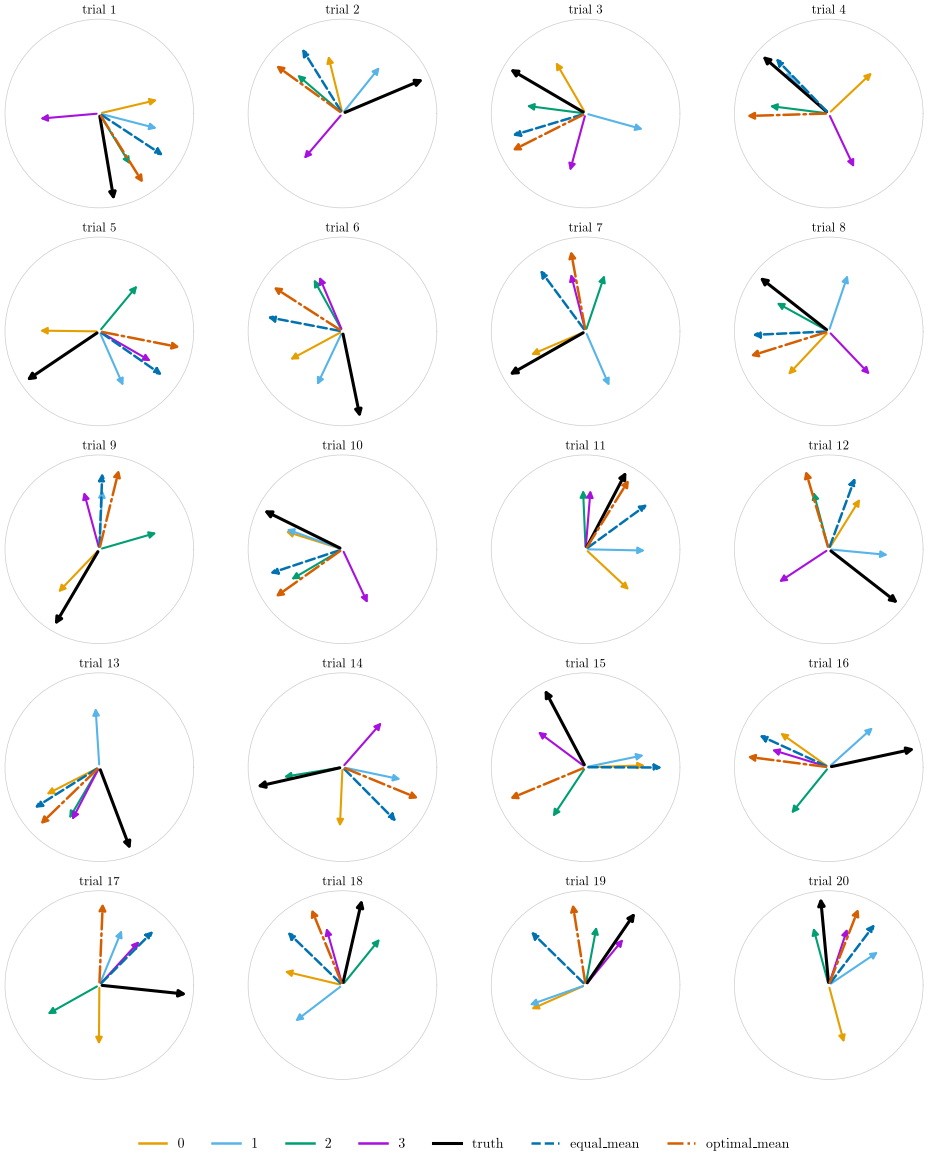

In [5]:
stimulus_fig, stimulus_axes = csa.plot_stimulus_circles(stimuli, source_idx)


## Choice simulator

In [6]:
sim_params = SimParams(alpha=0.20, gamma=0.80, kappa_p=16.0, kappa_a=4.0)
masked_report = stimulus_batch.source_choices
hidden_source = stimulus_batch.hidden_source
sim_result = simulate_choices(
    jax.random.PRNGKey(SEED + 2), sim_params, masked_report, hidden_source
)
choices = sim_result.choices
choice_trace = csa.trace_frame(sim_result, N_SOURCES, COUPLED)
choice_trace.assign(choice_deg=np.degrees(np.asarray(choices).ravel())).round(1)


,round,trial,coupled_agreement_score,coupled_weight,independent_weight,mu_rad,truth_mu_rad,hidden_mu_rad,choice_logpdf,is_probe,hidden_source,choice_deg
0,1,1,0.0,0.2,0.2,2.8,2.8,2.8,0.4,True,3.0,155.899994
1,1,2,0.1,0.2,0.3,5.6,5.6,NaN,-0.5,False,NaN,342.299988
2,1,3,0.2,0.2,0.3,5.7,5.8,5.7,0.4,True,1.0,325.399994
3,1,4,0.2,0.2,0.3,2.6,2.5,2.6,-0.5,True,1.0,168.699997
4,1,5,0.2,0.2,0.3,2.1,2.0,2.1,0.4,True,1.0,127.000000
5,1,6,0.2,0.2,0.3,2.3,2.5,2.3,-0.2,True,0.0,150.699997
6,1,7,0.2,0.2,0.3,2.9,3.4,2.9,0.3,True,1.0,173.399994
7,1,8,0.2,0.2,0.3,2.0,2.3,2.0,-1.7,True,3.0,84.199997
8,1,9,0.2,0.2,0.3,3.2,3.1,3.2,0.4,True,0.0,177.699997
9,1,10,0.2,0.2,0.3,4.9,4.9,4.9,0.4,True,3.0,276.100006


## Parameter effects

In [7]:
N_EFFECT_RUNS: int = 128
N_EFFECT_TRIALS: int = 80
EFFECT_SIGMA: jax.Array = jnp.asarray(0.55)
EFFECT_COLORS = ("#0072B2", "#009E73", "#D55E00")
EFFECT_CONFIG = dict(
    n_runs=N_EFFECT_RUNS,
    n_trials=N_EFFECT_TRIALS,
    n_sources=N_SOURCES,
    sigma=EFFECT_SIGMA,
    coupled=COUPLED,
)

sns.set_theme(style="whitegrid", context="notebook")


### Learning rate

The learning rate alpha controls how much each new agreement observation moves the score. The two figures below use the same simulated agreement-score matrices: first the coupled pair, then the average across the five non-coupled pairs. Shading is plus or minus one standard deviation across simulated runs; the right-side number labels the dashed expected-agreement limit.


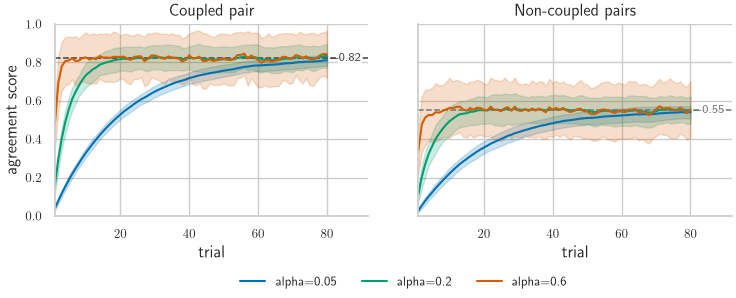

In [8]:
learning_reports = csa.generate_effect_reports(
    jax.random.PRNGKey(SEED + 10), lam=jnp.asarray(LAM), **EFFECT_CONFIG
)
learning_specs = [
    csa.EffectSpec(
        f"alpha={alpha}",
        color,
        SimParams(alpha=alpha, gamma=0.80, kappa_p=16.0, kappa_a=4.0),
    )
    for alpha, color in zip((0.05, 0.20, 0.60), EFFECT_COLORS)
]
learning_agreement_df = csa.agreement_sweep_frame(
    learning_reports, learning_specs, N_SOURCES, COUPLED
)
learning_targets_df = csa.fixed_agreement_targets_frame(
    learning_reports, kappa_a=4.0, n_sources=N_SOURCES, coupled=COUPLED
)

learning_fig, learning_axes = csa.plot_effect_lines(
    learning_agreement_df,
    learning_targets_df,
    "agreement score",
    (0, 1),
    csa.sweep_palette(learning_specs),
    n_trials=N_EFFECT_TRIALS,
)


### Agreement kernel

The agreement-kernel concentration kappa_a changes the agreement signal itself. The two figures below use the same simulated agreement-score matrices: first the coupled pair, then the average across the five non-coupled pairs. Each dashed line is the expected-agreement limit for that kappa_a, with the value shown at the right.


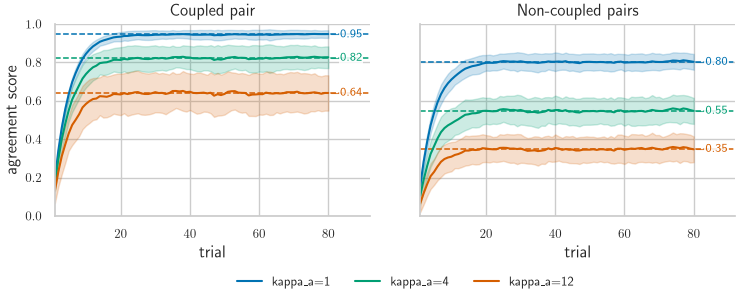

In [9]:
kernel_reports = csa.generate_effect_reports(
    jax.random.PRNGKey(SEED + 20), lam=jnp.asarray(LAM), **EFFECT_CONFIG
)
kernel_specs = [
    csa.EffectSpec(
        f"kappa_a={kappa_a:g}",
        color,
        SimParams(alpha=0.20, gamma=0.80, kappa_p=16.0, kappa_a=kappa_a),
        target_kappa_a=kappa_a,
    )
    for kappa_a, color in zip((1.0, 4.0, 12.0), EFFECT_COLORS)
]
kernel_agreement_df = csa.agreement_sweep_frame(
    kernel_reports, kernel_specs, N_SOURCES, COUPLED
)
kernel_targets_df = csa.kernel_targets_frame(
    kernel_reports, kernel_specs, N_SOURCES, COUPLED
)

kernel_fig, kernel_axes = csa.plot_effect_lines(
    kernel_agreement_df,
    kernel_targets_df,
    "agreement score",
    (0, 1),
    csa.sweep_palette(kernel_specs),
    n_trials=N_EFFECT_TRIALS,
)


### Coupling-use fraction

The coupling-use fraction gamma controls how much the learned agreement scores enter the working covariance. Gamma does not change learning; it changes how strongly learned coupling changes the aggregation weights. These figures average many simulated runs, so the curves show convergence of the mean source weights rather than one noisy sequence. Dashed lines show the target weights implied by the expected agreement scores. The gamma=0 curve is the no-use case: agreement is still learned in the simulation, but it is multiplied by zero when forming the weights.


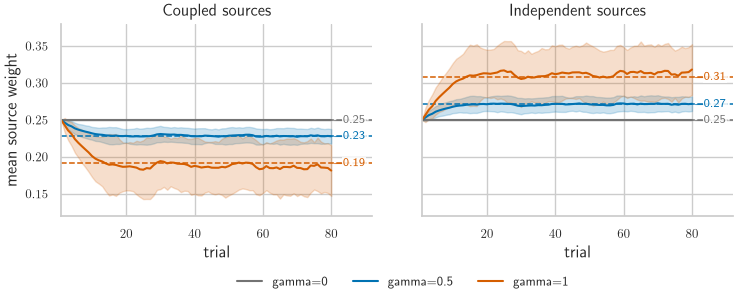

In [10]:
weight_reports = csa.generate_effect_reports(
    jax.random.PRNGKey(SEED + 30), lam=jnp.asarray(LAM), **EFFECT_CONFIG
)
weight_specs = [
    csa.EffectSpec(
        f"gamma={gamma:g}",
        color,
        SimParams(alpha=0.20, gamma=gamma, kappa_p=16.0, kappa_a=4.0),
    )
    for gamma, color in zip((0.0, 0.50, 1.0), ("0.45", "#0072B2", "#D55E00"))
]
weight_df = csa.weight_sweep_frame(weight_reports, weight_specs, N_SOURCES, COUPLED)
weight_targets_df = csa.weight_targets_frame(
    weight_reports, weight_specs, N_SOURCES, COUPLED, kappa_a=4.0
)

weight_fig, weight_axes = csa.plot_effect_lines(
    weight_df,
    weight_targets_df,
    "mean source weight",
    (0.12, 0.38),
    csa.sweep_palette(weight_specs),
    n_trials=N_EFFECT_TRIALS,
)


### Response concentration

The response concentration kappa_p controls response noise around the model predicted angle. It does not change the learned agreement scores or the predicted mean. The line shows the median absolute circular error across repeated simulator draws, with the shaded band showing the interquartile range.


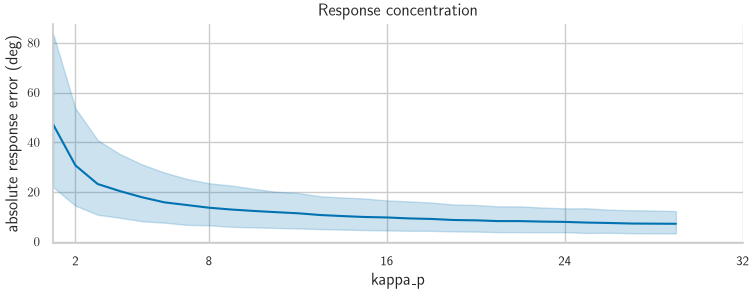

In [11]:
response_reports = csa.generate_effect_reports(
    jax.random.PRNGKey(SEED + 40), lam=jnp.asarray(LAM), **EFFECT_CONFIG
)
response_source_choices = response_reports[0].T[:, None, :]
response_hidden_source = jnp.full((1, N_EFFECT_TRIALS), jnp.nan)
response_result = simulate_choices(
    jax.random.PRNGKey(SEED + 41),
    SimParams(alpha=0.20, gamma=0.80, kappa_p=16.0, kappa_a=4.0),
    response_source_choices,
    response_hidden_source,
)
response_mu_deg = np.degrees(np.asarray(response_result.trace.response_mean).ravel())
response_kappa_values = np.arange(1.0, 30.0, 1.0)
response_error_df = csa.response_error_frame(
    jax.random.PRNGKey(SEED + 60),
    response_kappa_values,
    n_runs=N_EFFECT_RUNS,
    source_choices=response_source_choices,
    hidden_source=response_hidden_source,
    response_mu_deg=response_mu_deg,
)

response_fig, response_ax = csa.plot_response_error(response_error_df, response_kappa_values)


## NumPyro model

The fitted model is imported from `coupling_sources.core.model.choice_model`. The same model can expose intermediate deterministic sites with `debug=True`, while fitting uses the default `debug=False` path.


In [12]:
example_simulator_output = {
    "choices": choices,
    "source_choices": masked_report,
    "hidden_source": hidden_source,
}
example_metadata = {"coupled_sources": COUPLED}
model_site_trace = numpyro.handlers.trace(
    numpyro.handlers.seed(choice_model, jax.random.PRNGKey(SEED + 80))
).get_trace(example_simulator_output, example_metadata, debug=True)

pd.DataFrame([
    {
        "site": name,
        "type": site["type"],
        "observed": site.get("is_observed", False),
        "shape": tuple(np.shape(np.asarray(site["value"]))),
    }
    for name, site in model_site_trace.items()
    if site["type"] in {"sample", "deterministic"}
])


,site,type,observed,shape
0,source_reports_input,deterministic,False,"(4, 1, 40)"
1,hidden_source_input,deterministic,False,"(1, 40)"
2,alpha,sample,False,()
3,gamma,sample,False,()
4,kappa_p,sample,False,()
5,kappa_a,sample,False,()
6,is_probe_trial,deterministic,False,"(1, 40)"
7,visible_source_mask,deterministic,False,"(1, 40, 4)"
8,pre_update_agreement_scores,deterministic,False,"(1, 40, 4, 4)"
9,source_weights,deterministic,False,"(1, 40, 4)"


### Graphical view

The graph renders the imported `choice_model` with `debug=True`, so intermediate deterministic sites are visible here but are not generated during ordinary MCMC fitting.


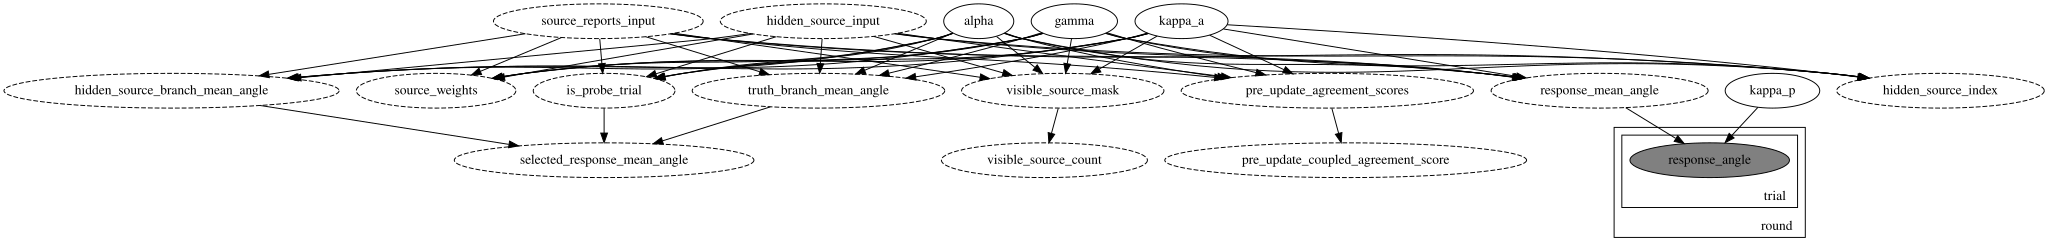

In [13]:
numpyro.render_model(
    choice_model,
    model_args=(example_simulator_output, example_metadata),
    model_kwargs={"debug": True},
    render_distributions=False,
    render_params=False,
)


## Predictive check

This section fixes several observation rounds for one participant, simulates choices, draws choices from the NumPyro model with the same fixed participant parameters via `numpyro.infer.Predictive`, and compares both deterministic response means and sampled choices. `source_choices` is source-first with shape `(source, round, time)`.


In [14]:
OBS_SEED: int = 101
OBS_N_ROUNDS: int = 40
OBS_N_TRIALS_FULL: int = 20
OBS_N_TRIALS_PARTIAL: int = 20
OBS_N_TRIALS: int = OBS_N_TRIALS_FULL + OBS_N_TRIALS_PARTIAL
OBS_SIGMA: jax.Array = jnp.asarray(0.55)
OBS_LAM: jax.Array = jnp.asarray(LAM)


In [15]:
def fixed_participant_samples(params: SimParams) -> dict[str, jax.Array]:
    return {
        "alpha": jnp.reshape(params.alpha, (1,)),
        "gamma": jnp.reshape(params.gamma, (1,)),
        "kappa_p": jnp.reshape(params.kappa_p, (1,)),
        "kappa_a": jnp.reshape(params.kappa_a, (1,)),
    }


predictive_params = SimParams(alpha=0.5592009, gamma=0.40267193, kappa_p=5.1099005, kappa_a=60.39794)
predictive_participant_samples = fixed_participant_samples(predictive_params)
pd.Series({k: float(np.asarray(v[0])) for k, v in predictive_participant_samples.items()})


alpha       0.559201
gamma       0.402672
kappa_p     5.109900
kappa_a    60.397942
dtype: float64

In [16]:
obs_batch = generate_stimuli(
    jax.random.PRNGKey(OBS_SEED),
    n_rounds=OBS_N_ROUNDS,
    n_trials_full=OBS_N_TRIALS_FULL,
    n_trials_partial=OBS_N_TRIALS_PARTIAL,
    n_sources=N_SOURCES,
    sigma=OBS_SIGMA,
    lam=OBS_LAM,
    coupled=COUPLED,
)
obs_source_choices = obs_batch.source_choices
obs_hidden_source = obs_batch.hidden_source
simulated_result = simulate_choices(
    jax.random.PRNGKey(OBS_SEED + 2),
    predictive_params,
    obs_source_choices,
    obs_hidden_source,
)
simulated_choices = simulated_result.choices
simulated_mean = simulated_result.trace.response_mean

round_idx = np.repeat(np.arange(1, OBS_N_ROUNDS + 1), OBS_N_TRIALS)
trial_idx = np.tile(np.arange(1, OBS_N_TRIALS + 1), OBS_N_ROUNDS)
pd.DataFrame({
    "round": round_idx,
    "trial": trial_idx,
    "is_probe": np.asarray(~jnp.isnan(obs_hidden_source)).ravel(),
    "hidden_source": np.asarray(obs_hidden_source).ravel(),
    "simulated_mean_deg": np.degrees(np.asarray(simulated_mean)).ravel(),
    "simulated_choice_deg": np.degrees(np.asarray(simulated_choices)).ravel(),
}).round(1)


,round,trial,is_probe,hidden_source,simulated_mean_deg,simulated_choice_deg
0,1,1,False,NaN,161.699997,185.000000
1,1,2,True,2.0,331.399994,306.700012
2,1,3,False,NaN,34.099998,355.899994
3,1,4,True,3.0,290.200012,304.000000
4,1,5,True,0.0,309.200012,295.100006
...,...,...,...,...,...,...
1595,40,36,True,2.0,171.100006,135.699997
1596,40,37,False,NaN,271.299988,338.200012
1597,40,38,True,3.0,228.699997,243.300003
1598,40,39,True,1.0,52.299999,8.600000


In [17]:
predictive_unobserved_output = {
    "choices": None,
    "source_choices": obs_source_choices,
    "hidden_source": obs_hidden_source,
}
predictive_draw = numpyro.infer.Predictive(
    choice_model,
    posterior_samples=predictive_participant_samples,
    return_sites=("response_angle", "response_mean_angle"),
)(
    jax.random.PRNGKey(OBS_SEED + 3),
    predictive_unobserved_output,
    None,
    debug=True,
)
model_choices = predictive_draw["response_angle"][0] % (2 * jnp.pi)
model_mean = predictive_draw["response_mean_angle"][0] % (2 * jnp.pi)

pd.DataFrame({
    "round": round_idx,
    "trial": trial_idx,
    "model_mean_deg": np.degrees(np.asarray(model_mean)).ravel(),
    "model_choice_deg": np.degrees(np.asarray(model_choices)).ravel(),
}).round(1)


,round,trial,model_mean_deg,model_choice_deg
0,1,1,161.699997,153.699997
1,1,2,331.399994,7.600000
2,1,3,34.099998,20.000000
3,1,4,290.200012,264.799988
4,1,5,309.200012,316.399994
...,...,...,...,...
1595,40,36,171.100006,171.300003
1596,40,37,271.299988,262.500000
1597,40,38,228.699997,235.800003
1598,40,39,52.299999,79.199997


In [18]:
mean_distance_deg = np.abs(
    np.degrees(np.asarray(centered_angle(simulated_mean - model_mean)))
)
choice_distance_deg = np.abs(
    np.degrees(np.asarray(centered_angle(simulated_choices - model_choices)))
)
predictive_distance = pd.DataFrame({
    "round": round_idx,
    "trial": trial_idx,
    "is_probe": np.asarray(~jnp.isnan(obs_hidden_source)).ravel(),
    "simulated_mean_deg": np.degrees(np.asarray(simulated_mean)).ravel(),
    "model_mean_deg": np.degrees(np.asarray(model_mean)).ravel(),
    "mean_distance_deg": mean_distance_deg.ravel(),
    "simulated_choice_deg": np.degrees(np.asarray(simulated_choices)).ravel(),
    "model_choice_deg": np.degrees(np.asarray(model_choices)).ravel(),
    "choice_distance_deg": choice_distance_deg.ravel(),
})
distance_summary = pd.Series({
    "mean_of_mean_distance_deg": predictive_distance.mean_distance_deg.mean(),
    "max_mean_distance_deg": predictive_distance.mean_distance_deg.max(),
    "mean_choice_distance_deg": predictive_distance.choice_distance_deg.mean(),
    "median_choice_distance_deg": predictive_distance.choice_distance_deg.median(),
    "max_choice_distance_deg": predictive_distance.choice_distance_deg.max(),
})

display(distance_summary.round(2))
predictive_distance.round(1)


mean_of_mean_distance_deg       0.000000
max_mean_distance_deg           0.000000
mean_choice_distance_deg       29.799999
median_choice_distance_deg     25.280001
max_choice_distance_deg       145.529999
dtype: float32

,round,trial,is_probe,simulated_mean_deg,model_mean_deg,mean_distance_deg,simulated_choice_deg,model_choice_deg,choice_distance_deg
0,1,1,False,161.699997,161.699997,0.0,185.000000,153.699997,31.299999
1,1,2,True,331.399994,331.399994,0.0,306.700012,7.600000,60.900002
2,1,3,False,34.099998,34.099998,0.0,355.899994,20.000000,24.100000
3,1,4,True,290.200012,290.200012,0.0,304.000000,264.799988,39.200001
4,1,5,True,309.200012,309.200012,0.0,295.100006,316.399994,21.299999
...,...,...,...,...,...,...,...,...,...
1595,40,36,True,171.100006,171.100006,0.0,135.699997,171.300003,35.599998
1596,40,37,False,271.299988,271.299988,0.0,338.200012,262.500000,75.699997
1597,40,38,True,228.699997,228.699997,0.0,243.300003,235.800003,7.500000
1598,40,39,True,52.299999,52.299999,0.0,8.600000,79.199997,70.599998


## MCMC fit

Fit the direct single-participant NumPyro model to the simulated choices and summarize the posterior for the four participant/model parameters.


  0%|          | 0/1200 [00:00<?, ?it/s]

  0%|          | 0/1200 [00:00<?, ?it/s]

  0%|          | 0/1200 [00:00<?, ?it/s]

,true,mean,sd,q05,median,q95
alpha,0.559,0.418,0.168,0.170,0.400,0.726
gamma,0.403,0.227,0.082,0.098,0.223,0.369
kappa_p,5.110,5.222,0.172,4.940,5.221,5.515
kappa_a,60.398,7.178,4.027,2.554,6.318,14.816


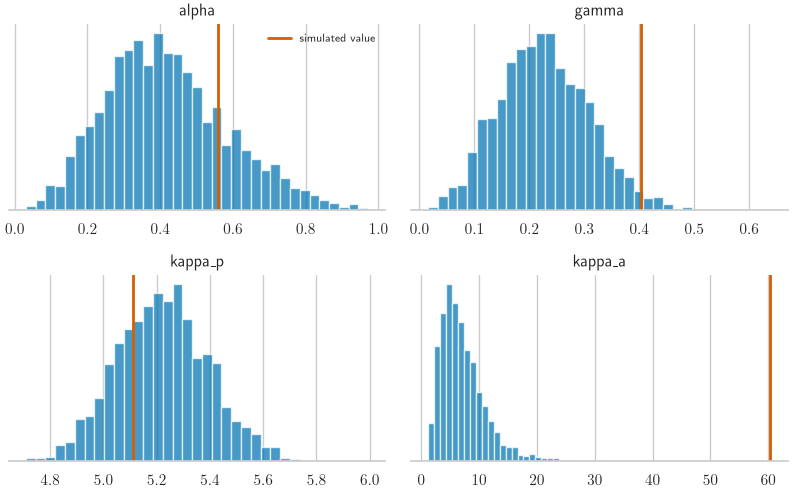

In [19]:
mcmc = fit_mcmc(
    jax.random.PRNGKey(OBS_SEED + 4),
    choices=simulated_choices,
    source_choices=obs_source_choices,
    hidden_source=obs_hidden_source,
    num_warmup=300,
    num_samples=900,
    num_chains=MCMC_NUM_CHAINS,
    chain_method=MCMC_CHAIN_METHOD,
    progress_bar=True,
    model_debug=False,
)
posterior_samples = mcmc.get_samples()
parameter_names = predictive_params.names()
posterior_frame = pd.DataFrame({name: np.asarray(posterior_samples[name]) for name in parameter_names})
true_values = csa.parameter_values(predictive_params)
posterior_summary = csa.posterior_summary(posterior_frame, true_values)

posterior_fig, posterior_axes = csa.plot_posterior_histograms(posterior_frame, true_values)
posterior_summary.round(3)
